# Importar datos de kaggle a google colab

Descargar la libreria para poder extraer los datasets

In [ ]:
!pip install opendatasets
import opendatasets as od

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


Descargar el dataset

In [1]:
dataset_link="https://www.kaggle.com/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes"
od.download(dataset_link)

NameError: name 'od' is not defined

Verificacion de que esten los datos esperados del dataset

In [ ]:
import os
os.rename("/content/mri-for-brain-tumor-with-bounding-boxes", "/content/dataset")
os.chdir("/content/dataset")
os.listdir()

FileNotFoundError: [Errno 2] No such file or directory: '/content/mri-for-brain-tumor-with-bounding-boxes' -> '/content/dataset'

Creacion de directorios base para el proyecto

In [ ]:
os.makedirs("/content/imagenes_tumores", exist_ok=True)
os.makedirs("/content/labels_tumores", exist_ok=True)

os.makedirs("/content/entrenamiento", exist_ok=True)

os.makedirs("/content/entrenamiento/images", exist_ok=True)
os.makedirs("/content/entrenamiento/images/train", exist_ok=True)
os.makedirs("/content/entrenamiento/images/val", exist_ok=True)
os.makedirs("/content/entrenamiento/images/test", exist_ok=True)

os.makedirs("/content/entrenamiento/labels", exist_ok=True)
os.makedirs("/content/entrenamiento/labels/train", exist_ok=True)
os.makedirs("/content/entrenamiento/labels/val", exist_ok=True)
os.makedirs("/content/entrenamiento/labels/test", exist_ok=True)


Mapeo de direcciones de carpetas

In [ ]:
imagenes_generales = "/content/imagenes_tumores/"

images_train = "/content/entrenamiento/images/train/"
images_val = "/content/entrenamiento/images/val/"
images_test = "/content/entrenamiento/images/test/"

labels_generales = "/content/labels_tumores/"

labels_train = "/content/entrenamiento/labels/train/"
labels_val = "/content/entrenamiento/labels/val/"
labels_test = "/content/entrenamiento/labels/test/"

In [ ]:
dataset_imagenes_train_glioma = '/content/dataset/Train/Glioma/images/'
dataset_imagenes_train_meningioma = '/content/dataset/Train/Meningioma/images/'
dataset_imagenes_train_pituitary = '/content/dataset/Train/Pituitary/images/'

datset_imagenes_val_glioma = '/content/dataset/Val/Glioma/images/'
datset_imagenes_val_meningioma = '/content/dataset/Val/Meningioma/images/'
datset_imagenes_val_pituitary = '/content/dataset/Val/Pituitary/images/'

In [ ]:
dataset_labels_train_glioma = '/content/dataset/Train/Glioma/labels/'
dataset_labels_train_meningioma = '/content/dataset/Train/Meningioma/labels/'
dataset_labels_train_pituitary = '/content/dataset/Train/Pituitary/labels/'

dataset_labels_val_glioma = '/content/dataset/Val/Glioma/labels/'
dataset_labels_val_meningioma = '/content/dataset/Val/Meningioma/labels/'
dataset_labels_val_pituitary = '/content/dataset/Val/Pituitary/labels/'

# Teoria 1:
Enternamiento del modelo con la estructura original del datset para evaluar su eficiencia antes de realizar otras operaciones.

Movemos todas las imagenes del dataset en su respectiva carpeta de entrenamiento. Las carpetas a utilizar son la carpeta train y val, test no se cuenta por que el dataset no cuenta con imagenes para test.

In [ ]:
import shutil
import os

datasets = {
    "train": {
        "Glioma": "/content/dataset/Train/Glioma/images/",
        "Meningioma": "/content/dataset/Train/Meningioma/images/",
        "Pituitary": "/content/dataset/Train/Pituitary/images/"
    },
    "val": {
        "Glioma": "/content/dataset/Val/Glioma/images/",
        "Meningioma": "/content/dataset/Val/Meningioma/images/",
        "Pituitary": "/content/dataset/Val/Pituitary/images/"
    }
}

images_train = "/content/entrenamiento/images/train/"
images_val = "/content/entrenamiento/images/val/"

def copy_images(source_folder, destination_folder):
    if not os.path.exists(destination_folder):
        os.makedirs(destination_folder)

    for filename in os.listdir(source_folder):
        source_path = os.path.join(source_folder, filename)
        destination_path = os.path.join(destination_folder, filename)

        if os.path.isfile(source_path):
            shutil.copy2(source_path, destination_path)

for category, path in datasets["train"].items():
    copy_images(path, images_train)

for category, path in datasets["val"].items():
    copy_images(path, images_val)

print("Todas las imágenes han sido copiadas correctamente.")


Todas las imágenes han sido copiadas correctamente.


Se debe de comprobar el tamaño de las imagenes.

In [ ]:
import os
from PIL import Image

image_dirs = [
    "/content/entrenamiento/images/train/",
    "/content/entrenamiento/images/val/"
]

def get_image_sizes(image_dirs):
    image_sizes = set()
    for image_dir in image_dirs:
        if os.path.exists(image_dir):
            for root, dirs, files in os.walk(image_dir):
                for file in files:
                    if file.endswith(('.jpg', '.jpeg', '.png')):
                        image_path = os.path.join(root, file)
                        with Image.open(image_path) as img:
                            image_sizes.add(img.size)
    return image_sizes

image_sizes = get_image_sizes(image_dirs)

print(f"Cantidad de tamaños diferentes de imágenes: {len(image_sizes)}")
print("Tamaños diferentes de imágenes (en píxeles):")
for size in image_sizes:
    print(size)


Cantidad de tamaños diferentes de imágenes: 130
Tamaños diferentes de imágenes (en píxeles):
(257, 320)
(209, 225)
(278, 306)
(411, 396)
(491, 624)
(721, 903)
(503, 369)
(338, 345)
(552, 527)
(200, 252)
(201, 251)
(318, 354)
(485, 510)
(420, 264)
(306, 306)
(289, 354)
(528, 581)
(204, 249)
(554, 554)
(330, 355)
(324, 284)
(200, 236)
(470, 432)
(264, 336)
(374, 370)
(530, 526)
(214, 216)
(1275, 1427)
(201, 207)
(229, 223)
(212, 237)
(213, 236)
(645, 439)
(323, 342)
(216, 216)
(290, 339)
(305, 337)
(209, 241)
(351, 398)
(630, 423)
(300, 359)
(400, 400)
(300, 258)
(306, 365)
(502, 502)
(455, 500)
(291, 340)
(685, 681)
(298, 354)
(374, 456)
(315, 315)
(472, 546)
(329, 314)
(256, 256)
(257, 248)
(312, 401)
(369, 398)
(239, 224)
(313, 393)
(940, 900)
(250, 270)
(225, 225)
(272, 331)
(262, 308)
(254, 325)
(200, 235)
(366, 395)
(216, 234)
(474, 474)
(591, 650)
(450, 446)
(238, 212)
(442, 442)
(534, 674)
(257, 307)
(224, 219)
(402, 396)
(341, 377)
(213, 237)
(341, 395)
(441, 427)
(825, 993)
(21

Movemos todas las etiquetas del dataset en su lugar correspondiente dentro de la carpeta entrenamiento

In [ ]:
import shutil
import os

datasets_labels = {
    "train": {
        "Glioma": "/content/dataset/Train/Glioma/labels/",
        "Meningioma": "/content/dataset/Train/Meningioma/labels/",
        "Pituitary": "/content/dataset/Train/Pituitary/labels/"
    },
    "val": {
        "Glioma": "/content/dataset/Val/Glioma/labels/",
        "Meningioma": "/content/dataset/Val/Meningioma/labels/",
        "Pituitary": "/content/dataset/Val/Pituitary/labels/"
    }
}

labels_train = "/content/entrenamiento/labels/train/"
labels_val = "/content/entrenamiento/labels/val/"

def copy_labels(source_folder, destination_folder):
    if not os.path.exists(destination_folder):
        os.makedirs(destination_folder)

    for filename in os.listdir(source_folder):
        source_path = os.path.join(source_folder, filename)
        destination_path = os.path.join(destination_folder, filename)

        if os.path.isfile(source_path):
            shutil.copy2(source_path, destination_path)

for category, path in datasets_labels["train"].items():
    copy_labels(f"{path}", f"{labels_train}")

for category, path in datasets_labels["val"].items():
    copy_labels(f"{path}", f"{labels_val}")

print("Todas las etiquetas han sido copiadas correctamente.")


Todas las etiquetas han sido copiadas correctamente.


El dataet cuenta con labels etiquetadas y no vamos a ocupar las etiquetas que tengan la clases no tumor por ser irrelevante en el estudio.
Se debe de cambiar el id del tumor Pituitary ya que no debe de ser 3 si no 2

El mapeo nuevo es el siguiente:
*   Class 0: Glioma
*   Class 1: Meningioma
*   Class 2: Pituitary

In [ ]:
import os

labels_train = "/content/entrenamiento/labels/train/"
labels_val = "/content/entrenamiento/labels/val/"

def update_labels(folder):
    for filename in os.listdir(folder):
        file_path = os.path.join(folder, filename)

        if os.path.isfile(file_path) and filename.endswith(".txt"):
            with open(file_path, "r") as file:
                lines = file.readlines()

            new_lines = []
            for line in lines:
                values = line.strip().split()
                if values:
                    class_id = values[0]
                    if class_id == "3":
                        values[0] = "2"
                    new_lines.append(" ".join(values))

            with open(file_path, "w") as file:
                file.write("\n".join(new_lines) + "\n")

update_labels(labels_train)
update_labels(labels_val)

print("Mapeo de clases actualizado en los archivos de etiquetas.")


Mapeo de clases actualizado en los archivos de etiquetas.


Contamos cuantas detecciones tenemos por cada clase para verificar la distribucion de los datos

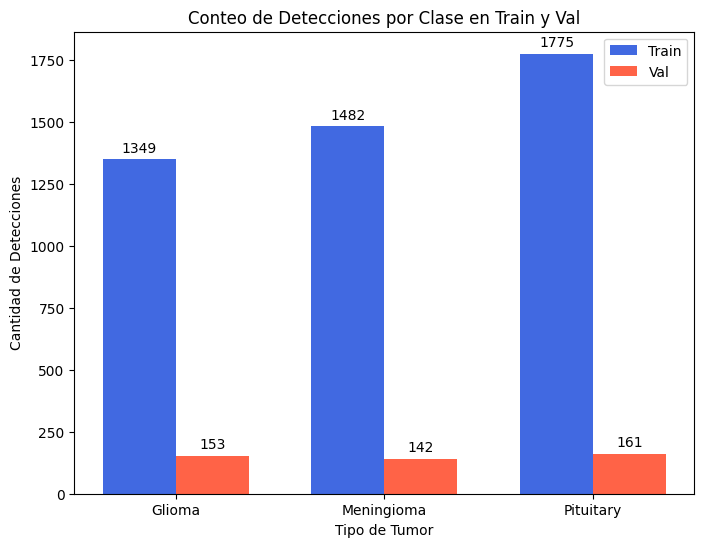

In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np

labels_train = "/content/entrenamiento/labels/train/"
labels_val = "/content/entrenamiento/labels/val/"

detections_train = {"Glioma": 0, "Meningioma": 0, "Pituitary": 0}
detections_val = {"Glioma": 0, "Meningioma": 0, "Pituitary": 0}

def count_detections(folder, detections_dict):
    for filename in os.listdir(folder):
        file_path = os.path.join(folder, filename)

        if os.path.isfile(file_path) and filename.endswith(".txt"):
            with open(file_path, "r") as file:
                lines = file.readlines()

            for line in lines:
                values = line.strip().split()
                if values:
                    class_id = values[0]
                    if class_id == "0":
                        detections_dict["Glioma"] += 1
                    elif class_id == "1":
                        detections_dict["Meningioma"] += 1
                    elif class_id == "2":
                        detections_dict["Pituitary"] += 1

count_detections(labels_train, detections_train)
count_detections(labels_val, detections_val)

labels = ["Glioma", "Meningioma", "Pituitary"]
train_counts = [detections_train[label] for label in labels]
val_counts = [detections_val[label] for label in labels]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 6))
bars1 = ax.bar(x - width/2, train_counts, width, label="Train", color="royalblue")
bars2 = ax.bar(x + width/2, val_counts, width, label="Val", color="tomato")

ax.set_xlabel("Tipo de Tumor")
ax.set_ylabel("Cantidad de Detecciones")
ax.set_title("Conteo de Detecciones por Clase en Train y Val")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f"{height}",
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha="center", va="bottom")

plt.show()


Se sube el archivo .yaml para obtener de ahi todas las especificaciones del entrenamiento.

Se descarga la libreria Ultralytics

In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 976.9/976.9 kB 21.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 109.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 84.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 60.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 93.6 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstal

Se realiza el entramiento

In [ ]:
from ultralytics import YOLO

os.makedirs("/content/resultados_train", exist_ok=True)
yaml_file = "/content/datos_traint.yaml"

model = YOLO("yolo11n.pt")

model.train(data=yaml_file,
            epochs=10, batch=2,
            imgsz=640,
            project='/content/resultados_train',
            name='entrenamiento_yolo11n'
)


Ultralytics 8.3.86 🚀 Python-3.11.11 torch-2.5.1+cu124 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: task=detect, mode=train, model=yolo11n.pt, data=/content/datos_traint.yaml, epochs=10, time=None, patience=100, batch=2, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=/content/resultados_train, name=entrenamiento_yolo11n2, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_txt=False, save_conf=False, save_crop=False, show_la

100%|██████████| 755k/755k [00:00<00:00, 41.5MB/s]


Overriding model.yaml nc=80 with nc=3

                   from  n    params  module                                       arguments                     
  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 
  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                
  2                  -1  1      6640  ultralytics.nn.modules.block.C3k2            [32, 64, 1, False, 0.25]      
  3                  -1  1     36992  ultralytics.nn.modules.conv.Conv             [64, 64, 3, 2]                
  4                  -1  1     26080  ultralytics.nn.modules.block.C3k2            [64, 128, 1, False, 0.25]     
  5                  -1  1    147712  ultralytics.nn.modules.conv.Conv             [128, 128, 3, 2]              
  6                  -1  1     87040  ultralytics.nn.modules.block.C3k2            [128, 128, 1, True]           
  7                  -1  1    295424  ultralytics

train: Scanning /content/entrenamiento/labels/train... 4026 images, 0 backgrounds, 0 corrupt: 100%|██████████| 4026/4026 [00:06<00:00, 582.10it/s]


train: New cache created: /content/entrenamiento/labels/train.cache
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, num_output_channels=3, method='weighted_average'), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))


...

                   all        412        456      0.915      0.888      0.945      0.743



10 epochs completed in 0.648 hours.
Optimizer stripped from /content/resultados_train/entrenamiento_yolo11n2/weights/last.pt, 5.5MB
Optimizer stripped from /content/resultados_train/entrenamiento_yolo11n2/weights/best.pt, 5.5MB

Validating /content/resultados_train/entrenamiento_yolo11n2/weights/best.pt...
Ultralytics 8.3.86 🚀 Python-3.11.11 torch-2.5.1+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLO11n summary (fused): 100 layers, 2,582,737 parameters, 0 gradients, 6.3 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 103/103 [00:06<00:00, 17.14it/s]


                   all        412        456      0.914      0.886      0.945      0.743
                Glioma        135        153       0.88       0.85      0.913      0.705
            Meningioma        140        142      0.961      0.965      0.991      0.798
             Pituitary        154        161        0.9      0.845      0.933      0.728
Speed: 0.4ms preprocess, 6.5ms inference, 0.0ms loss, 1.6ms postprocess per image
Results saved to /content/resultados_train/entrenamiento_yolo11n2


ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7ea4ce7cced0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

Validación del modelo entrenado

In [ ]:
model = YOLO('/content/resultados_train/entrenamiento_yolo11n2/weights/best.pt')

results = model.val(data=yaml_file, project='/content/resultados_train', name='evaluacion_yolo11n')

#print(results)

print("mAP@0.5:", results.box.map75)

Ultralytics 8.3.86 🚀 Python-3.11.11 torch-2.5.1+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLO11n summary (fused): 100 layers, 2,582,737 parameters, 0 gradients, 6.3 GFLOPs


val: Scanning /content/entrenamiento/labels/val.cache... 412 images, 1 backgrounds, 0 corrupt: 100%|██████████| 412/412 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 26/26 [00:05<00:00,  4.84it/s]


                   all        412        456      0.914      0.886      0.945      0.745
                Glioma        135        153       0.88       0.85      0.912      0.706
            Meningioma        140        142      0.961      0.965      0.991        0.8
             Pituitary        154        161        0.9      0.845      0.933       0.73
Speed: 1.6ms preprocess, 4.0ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to /content/resultados_train/evaluacion_yolo11n
ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7ea4ebc14210>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,   

Inferencia del modelo entrenado


image 1/1 /content/dataset/Val/Glioma/images/Tr-gl_0238.jpg: 640x640 1 Glioma, 13.0ms
Speed: 4.1ms preprocess, 13.0ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)


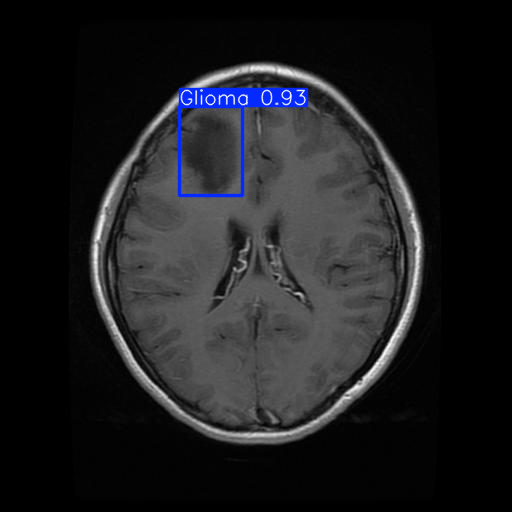

'/content/resultados_train/detection.jpg'

In [ ]:
import cv2
import matplotlib.pyplot as plt

img_path = "/content/dataset/Val/Glioma/images/Tr-gl_0238.jpg"

img = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

results = model(img_path)

result = results[0]

result.show()

result.save('/content/resultados_train/detection.jpg')


Comprimo la carpeta de resultados para descargarla en un archivo .zip

In [ ]:
import shutil

carpeta_a_comprimir = "/content/resultados_train/"

archivo_zip = "/content/resultados.zip"

shutil.make_archive(archivo_zip.replace('.zip', ''), 'zip', carpeta_a_comprimir)


'/content/resultados.zip'

# Preprocesamiento de las etiquetas

In [ ]:
label_paths = {
    "Train_Glioma": "/content/dataset/Train/Glioma/labels/",
    "Train_Meningioma": "/content/dataset/Train/Meningioma/labels/",
    "Train_Pituitary": "/content/dataset/Train/Pituitary/labels/",
    "Val_Glioma": "/content/dataset/Val/Glioma/labels/",
    "Val_Meningioma": "/content/dataset/Val/Meningioma/labels/",
    "Val_Pituitary": "/content/dataset/Val/Pituitary/labels/",
}

def modificar_etiquetas(file_path):
    with open(file_path, "r") as f:
        lines = f.readlines()
    nuevas_lineas = []

    for line in lines:
        partes = line.split()
        if partes:
            if partes[0] == "0":
                partes[0] = "1"
            elif partes[0] == "1":
                partes[0] = "2"

        nuevas_lineas.append(" ".join(partes))

    with open(file_path, "w") as f:
        f.write("\n".join(nuevas_lineas))

for folder, path in label_paths.items():
    if os.path.exists(path):
        for file in os.listdir(path):
            if file.endswith(".txt"):
                file_path = os.path.join(path, file)
                modificar_etiquetas(file_path)

print("Todos los archivos han sido actualizados.")


NameError: name 'os' is not defined

In [ ]:
import shutil

os.makedirs(labels_generales, exist_ok=True)

for folder, path in label_paths.items():
    if os.path.exists(path):
        for file in os.listdir(path):
            if file.endswith(".txt"):
                origen = os.path.join(path, file)
                destino = os.path.join(labels_generales, file)

                shutil.move(origen, destino)

print("Todos los archivos han sido movidos a", labels_generales)

# Analisis general del contenido de los datos

In [ ]:
import os
from collections import Counter

class_counts = Counter()

for folder_name, path in label_paths.items():
    if os.path.exists(path):
        for file in os.listdir(path):
            if file.endswith(".txt"):
                file_path = os.path.join(path, file)

                with open(file_path, "r") as f:
                    for line in f:
                        class_id = line.split()[0]
                        class_counts[class_id] += 1

print("Conteo total de etiquetas por clase en el dataset:")
for class_id, count in sorted(class_counts.items()):
    print(f"Clase {class_id}: {count} etiquetas")


NameError: name 'label_paths' is not defined

In [ ]:
import matplotlib.pyplot as plt

sorted_classes = sorted(class_counts.items())

class_names = {
    "1": "Glioma",
    "2": "Meningioma",
    "3": "Pituitary"
}

class_labels = [class_names.get(cls, f"Clase {cls}") for cls, _ in sorted_classes]
counts = [count for _, count in sorted_classes]

plt.figure(figsize=(8, 5))
plt.bar(class_labels, counts, color=['blue', 'orange', 'green'])
plt.xlabel("Clases")
plt.ylabel("Número de etiquetas")
plt.title("Distribución de etiquetas por clase")
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()


In [ ]:
import os
from collections import Counter

images_paths = {
    "imagenes_generales": "/content/drive/MyDrive/NeuralScan/Imagenes/Imagenes y etiquetas juntas/imagenes/",
}

image_counts = Counter()

for folder_name, path in images_paths.items():
    if os.path.exists(path):
        for file in os.listdir(path):
            if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                image_counts[file] += 1

repeated_images = {name: count for name, count in image_counts.items() if count > 1}

if repeated_images:
    print("Imágenes duplicadas encontradas:")
    for image, count in repeated_images.items():
        print(f"{image}: {count} veces")
else:
    print("No hay imágenes duplicadas.")


In [ ]:
multi_line_files = 0

for folder_name, path in label_paths.items():
    if os.path.exists(path):
        for file in os.listdir(path):
            if file.endswith(".txt"):
                file_path = os.path.join(path, file)

                with open(file_path, "r") as f:
                    lines = f.readlines()

                if len(lines) >= 2:
                    multi_line_files += 1

print(f"Total de archivos con dos o más líneas (sin importar clase): {multi_line_files}")

In [ ]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

# 📌 Diccionario de clases
class_names = {
    "0": "Glioma",
    "1": "Meningioma",
    "3": "Pituitary"
}

# 📌 Definir rutas de etiquetas organizadas por tumor
label_paths = {
    "Train_Glioma": "/content/mri-for-brain-tumor-with-bounding-boxes/Train/Glioma/labels/",
    "Train_Meningioma": "/content/mri-for-brain-tumor-with-bounding-boxes/Train/Meningioma/labels/",
    "Train_Pituitary": "/content/mri-for-brain-tumor-with-bounding-boxes/Train/Pituitary/labels/",
    "Val_Glioma": "/content/mri-for-brain-tumor-with-bounding-boxes/Val/Glioma/labels/",
    "Val_Meningioma": "/content/mri-for-brain-tumor-with-bounding-boxes/Val/Meningioma/labels/",
    "Val_Pituitary": "/content/mri-for-brain-tumor-with-bounding-boxes/Val/Pituitary/labels/",
}

# 📌 Diccionario {imagen: [(archivo_txt, tumor_tipo), (archivo_txt, tumor_tipo), ...]}
image_dict = {}

for tumor_key, label_folder in label_paths.items():
    if not os.path.exists(label_folder):  # Evitar errores si la carpeta no existe
        continue

    for file in os.listdir(label_folder):
        if file.endswith(".txt"):  # Solo archivos de etiquetas
            txt_path = os.path.join(label_folder, file)

            # 📌 Leer todas las líneas del archivo y obtener las clases detectadas
            with open(txt_path, "r") as f:
                for line in f:
                    class_id = line.split()[0]  # Tomamos el primer número de cada línea
                    if class_id in class_names:
                        tumor_type = class_names[class_id]  # Convertimos al nombre del tumor

                        # 📌 Guardamos cada detección individualmente
                        if file not in image_dict:
                            image_dict[file] = []
                        image_dict[file].append((file, tumor_type))

# 📌 Lista de imágenes únicas (sin repetir detecciones)
all_images = list(image_dict.keys())

# 📌 Dividir 5% para test
test_size = int(len(all_images) * 0.05)
train_val_images, test_images = train_test_split(all_images, test_size=test_size, random_state=42)

# 📌 Dividir lo restante en 80% train y 20% val
train_size = int(len(train_val_images) * 0.8)
train_images, val_images = train_test_split(train_val_images, train_size=train_size, random_state=42)

# 📌 Función para crear DataFrame
def create_dataframe(image_list):
    data = []
    for img in image_list:
        data.extend(image_dict[img])  # Agregamos cada detección individualmente
    return pd.DataFrame(data, columns=["Archivo", "Tumor_Tipo"])

# 📌 Crear DataFrames
df_train = create_dataframe(train_images)
df_val = create_dataframe(val_images)
df_test = create_dataframe(test_images)

# 📌 Guardar CSVs
df_train.to_csv("train.csv", index=False)
df_val.to_csv("val.csv", index=False)
df_test.to_csv("test.csv", index=False)

print(f"✔ CSVs generados: train.csv ({len(df_train)} filas), val.csv ({len(df_val)} filas), test.csv ({len(df_test)} filas)")



InvalidParameterError: The 'test_size' parameter of train_test_split must be a float in the range (0.0, 1.0), an int in the range [1, inf) or None. Got 0 instead.

In [ ]:
import pandas as pd

# 📌 Definir rutas de los CSVs
tipos_csv = {
    "train": "/content/mri-for-brain-tumor-with-bounding-boxes/train.csv",
    "val": "/content/mri-for-brain-tumor-with-bounding-boxes/val.csv",
    "test": "/content/mri-for-brain-tumor-with-bounding-boxes/test.csv"
}

# 📌 Cargar los CSVs en DataFrames
dfs = {tipo: pd.read_csv(ruta) for tipo, ruta in tipos_csv.items()}

# 📌 Obtener conjuntos de nombres de archivos únicos
archivos_train = set(dfs["train"]["Archivo"])
archivos_val = set(dfs["val"]["Archivo"])
archivos_test = set(dfs["test"]["Archivo"])

# 📌 Verificar si hay archivos repetidos entre conjuntos
duplicados_train_val = archivos_train.intersection(archivos_val)
duplicados_train_test = archivos_train.intersection(archivos_test)
duplicados_val_test = archivos_val.intersection(archivos_test)

# 📌 Imprimir resultados
if not duplicados_train_val and not duplicados_train_test and not duplicados_val_test:
    print("✔ No hay archivos duplicados entre los conjuntos. Todo está correcto.")
else:
    print("⚠ Se encontraron archivos duplicados entre conjuntos:")
    if duplicados_train_val:
        print(f"   - Entre Train y Val: {duplicados_train_val}")
    if duplicados_train_test:
        print(f"   - Entre Train y Test: {duplicados_train_test}")
    if duplicados_val_test:
        print(f"   - Entre Val y Test: {duplicados_val_test}")




In [ ]:
import pandas as pd

# 📌 Definir rutas de los CSVs
tipos_csv = {
    "train": "/content/mri-for-brain-tumor-with-bounding-boxes/train.csv",
    "val": "/content/mri-for-brain-tumor-with-bounding-boxes/val.csv",
    "test": "/content/mri-for-brain-tumor-with-bounding-boxes/test.csv"
}

# 📌 Iterar por cada conjunto y calcular estadísticas
for tipo, ruta in tipos_csv.items():
    # 📌 Cargar CSV
    df = pd.read_csv(ruta)

    # 📌 Contar imágenes únicas
    total_imagenes = df["Archivo"].nunique()

    # 📌 Contar cantidad de tumores por tipo
    tumores_contados = df["Tumor_Tipo"].value_counts().to_dict()

    # 📌 Imprimir resultados
    print(f"\n📊 Estadísticas para {tipo.upper()}:")
    print(f"🔹 Total de imágenes únicas: {total_imagenes}")
    for tumor, cantidad in tumores_contados.items():
        print(f"   - {tumor}: {cantidad} detecciones")


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 📌 Definir rutas de los CSVs
tipos_csv = {
    "train": "/content/mri-for-brain-tumor-with-bounding-boxes/train.csv",
    "val": "/content/mri-for-brain-tumor-with-bounding-boxes/val.csv",
    "test": "/content/mri-for-brain-tumor-with-bounding-boxes/test.csv"
}

# 📌 Diccionarios para almacenar estadísticas
tumor_tipos = ["Glioma", "Meningioma", "Pituitary"]
colores = ["gray", "blue", "orange", "green"]

# 📌 Inicializar listas para los valores
total_imagenes = []
tumores_por_tipo = {tumor: [] for tumor in tumor_tipos}

# 📌 Iterar sobre cada conjunto (train, val, test)
for tipo, ruta in tipos_csv.items():
    df = pd.read_csv(ruta)

    # 📌 Contar imágenes únicas
    total_imagenes.append(df["Archivo"].nunique())

    # 📌 Contar cantidad de tumores por tipo
    tumores_contados = df["Tumor_Tipo"].value_counts().to_dict()

    # 📌 Guardar valores de tumores en sus listas correspondientes
    for tumor in tumor_tipos:
        tumores_por_tipo[tumor].append(tumores_contados.get(tumor, 0))

# 📌 Configurar la gráfica
x = np.arange(len(tipos_csv))  # Posiciones en el eje X
width = 0.2  # Ancho de cada barra

plt.figure(figsize=(10, 6))

# 📊 Agregar barras al gráfico
plt.bar(x - 1.5 * width, total_imagenes, width, color=colores[0], label="Total Imágenes")
for i, tumor in enumerate(tumor_tipos):
    plt.bar(x - 0.5 * width + i * width, tumores_por_tipo[tumor], width, color=colores[i + 1], label=tumor)

# 📌 Agregar etiquetas y títulos
plt.xlabel("Conjunto de Datos")
plt.ylabel("Cantidad")
plt.title("Distribución de Imágenes y Tumores por Conjunto")
plt.xticks(x, ["Train", "Val", "Test"])  # Etiquetas en X
plt.legend()  # Agregar leyenda

# 📌 Agregar etiquetas en las barras
for i in range(len(x)):
    plt.text(x[i] - 1.5 * width, total_imagenes[i] + 5, str(total_imagenes[i]), ha='center', fontsize=12, fontweight='bold')
    for j, tumor in enumerate(tumor_tipos):
        plt.text(x[i] - 0.5 * width + j * width, tumores_por_tipo[tumor][i] + 5, str(tumores_por_tipo[tumor][i]), ha='center', fontsize=12, fontweight='bold')

# 📌 Mostrar gráfica
plt.show()




# Exportar el modelo

In [ ]:
from ultralytics import YOLO
model = YOLO("/content/best.pt")
model.export(format='onnx')

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.3.99 🚀 Python-3.11.11 torch-2.6.0+cu124 CPU (Intel Xeon 2.20GHz)
YOLO11n summary (fused): 100 layers, 2,582,737 parameters, 0 gradients, 6.3 GFLOPs

PyTorch: starting from '/content/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (5.2 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0', 'onnxslim', 'onnxruntime'] not found, attempting AutoUpdate...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 219.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 144.1/144.1 kB 292.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 247.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

'/content/best.onnx'